# Bons e Maus Pagadores — Modelagem

Modelagem · Give Me Some Credit <br>
Por [Leonardo Dias Trindade da Silva](https://github.com/LeoDiasTrindade)

**Pergunta:** a partir do histórico de crédito de um cliente, qual a probabilidade de ele ter um atraso grave (90 dias ou mais) nos próximos 2 anos?

Este notebook continua o `01_eda.ipynb`. As regras de limpeza decididas na EDA foram movidas para `src/bons_maus_pagadores/preprocessamento.py`, para que EDA e modelagem usem exatamente a mesma regra.

**Roteiro** (cada passo remete a uma aula):
1. Divisão treino/teste estratificada; o teste fica trancado até o fim (Aula 10)
2. Pré-processamento dentro da Pipeline, sem leakage (Aula 10)
3. Baseline: por que acurácia engana (Aula 6)
4. Regressão logística: transformação log, ridge × lasso, escolha de C por validação cruzada (Aulas 9 e 11)
5. Random Forest: tamanho mínimo da folha e viés-variância (Aula 6 e aula de 13/11)
6. Avaliação final no teste: ROC/AUC e log-loss (Aulas 6 e 10)
7. Limiar de decisão e matriz de confusão (Aula 9)
8. Interpretação: odds ratio e importância das features (Aula 9)
9. Submissão Kaggle (opcional)

---

In [1]:
%matplotlib inline
import time, warnings
from pathlib import Path

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     cross_validate, cross_val_predict)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler, KBinsDiscretizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, log_loss, accuracy_score, roc_curve,
                             precision_recall_curve, confusion_matrix,
                             precision_score, recall_score)

from bons_maus_pagadores.preprocessamento import (
    TARGET_NAME, carregar_treino, carregar_teste_kaggle, preparar_features, log_cauda_longa)

# Aviso interno do sklearn 1.9 (RandomForest com n_jobs dentro do GridSearchCV); não afeta resultados
warnings.filterwarnings('ignore', message='.*sklearn.utils.parallel.delayed.*')

SEED = 42
RAIZ = Path.cwd().parent
FIG_DIR = RAIZ / 'docs' / 'paper' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
# Estilo dos gráficos (rótulos em inglês: as figuras vão para o artigo)
AZUL, LARANJA, VERDE = '#2a78d6', '#eb6834', '#1baf7a'
CINZA, TEXTO, TEXTO_2 = '#8a8984', '#0b0b0b', '#52514e'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'font.size': 10, 'axes.titlesize': 10.5, 'axes.labelsize': 10,
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': TEXTO_2, 'axes.titlecolor': TEXTO,
    'axes.titlelocation': 'left', 'xtick.color': TEXTO_2, 'ytick.color': TEXTO_2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.8,
    'axes.axisbelow': True, 'lines.linewidth': 2, 'legend.frameon': False,
})

def salvar(fig, nome):
    for ext in ('pdf', 'png'):
        fig.savefig(FIG_DIR / f'{nome}.{ext}')

NOMES_CURTOS = {
    'RevolvingUtilizationOfUnsecuredLines': 'Revolving utilization',
    'age': 'Age',
    'NumberOfTime30-59DaysPastDueNotWorse': 'Times 30-59 days late',
    'DebtRatio': 'Debt ratio',
    'MonthlyIncome': 'Monthly income',
    'NumberOfOpenCreditLinesAndLoans': 'Open credit lines',
    'NumberOfTimes90DaysLate': 'Times 90+ days late',
    'NumberRealEstateLoansOrLines': 'Real-estate loans',
    'NumberOfTime60-89DaysPastDueNotWorse': 'Times 60-89 days late',
    'NumberOfDependents': 'Dependents',
    'Missing-MonthlyIncome': 'Flag: income missing',
    'Missing-NumberOfDependents': 'Flag: dependents missing',
    'Atraso-codigo-invalido': 'Flag: late codes 96/98',
    'Rotativo-invalido': 'Flag: revolving > 400%',
}

## 1. Divisão treino/teste

Uso apenas o `cs-training.csv` (o `cs-test.csv` do Kaggle não tem rótulo). Separo 20% como **teste**, estratificado pelo alvo para manter a mesma taxa de inadimplência (6,7%) nos dois lados. O teste fica trancado: todas as escolhas (transformações, C, tamanho da folha, limiar) são feitas com validação cruzada estratificada de 5 folds dentro dos 80% de treino. O teste é aberto uma única vez, na seção 6 (Aula 10: *cross-validation chooses, the test grades*).

In [3]:
df = carregar_treino()
X, y = df.drop(columns=TARGET_NAME), df[TARGET_NAME]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

pd.DataFrame({'linhas': [len(y_treino), len(y_teste)],
              'inadimplentes': [y_treino.sum(), y_teste.sum()],
              'taxa': [y_treino.mean(), y_teste.mean()]},
             index=['treino', 'teste']).round(4)

,linhas,inadimplentes,taxa
treino,120000,8021,0.0668
teste,30000,2005,0.0668


### Resumo visual da EDA (só no treino)

Antes de modelar, uma figura que resume os achados do `01_eda` e que vai para o artigo. Uso apenas o treino para não olhar o teste.

- As contagens de atraso e o uso do rotativo têm relação forte e monotônica com a inadimplência.
- A idade tem relação decrescente.
- Os indicadores criados na EDA carregam informação: renda faltante tem taxa *menor* que a média, e os códigos 96/98 têm taxa de mais de 50%.

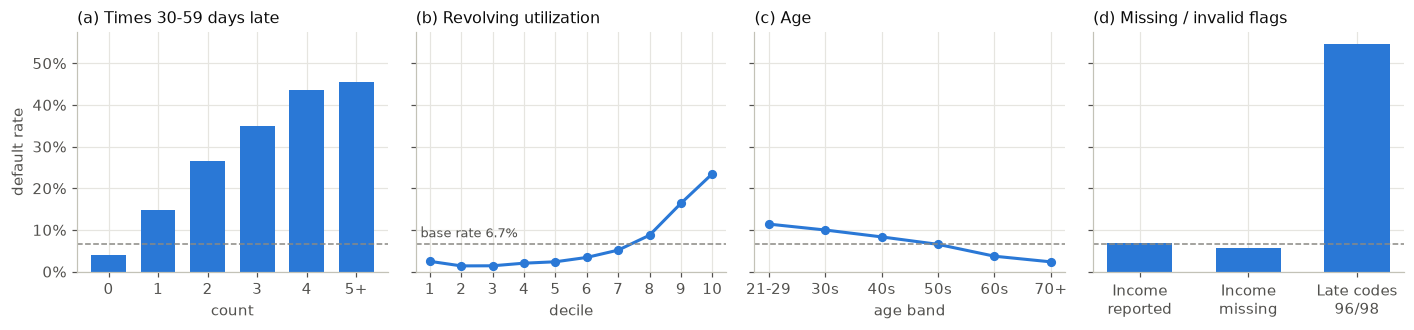

{'Income\nreported': np.float64(0.0696), 'Income\nmissing': np.float64(0.0557), 'Late codes\n96/98': np.float64(0.5467)}


In [4]:
eda = preparar_features(X_treino).assign(alvo=y_treino.values)
taxa_base = y_treino.mean()

fig, axes = plt.subplots(1, 4, figsize=(13, 3.1), sharey=True)

# (a) atrasos de 30-59 dias
atraso = eda['NumberOfTime30-59DaysPastDueNotWorse'].clip(upper=5)
t = eda.groupby(atraso)['alvo'].mean()
axes[0].bar(['0', '1', '2', '3', '4', '5+'], t.values, color=AZUL, width=0.7)
axes[0].set(title='(a) Times 30-59 days late', xlabel='count')

# (b) uso do rotativo por decil
decil = pd.qcut(eda['RevolvingUtilizationOfUnsecuredLines'], 10, labels=False) + 1
t = eda.groupby(decil)['alvo'].mean()
axes[1].plot(t.index, t.values, color=AZUL, marker='o', markersize=5)
axes[1].set(title='(b) Revolving utilization', xlabel='decile', xticks=range(1, 11))

# (c) idade em faixas
faixa = pd.cut(eda['age'], [20, 30, 40, 50, 60, 70, 110], right=False)
t = eda.groupby(faixa, observed=True)['alvo'].mean()
axes[2].plot(range(len(t)), t.values, color=AZUL, marker='o', markersize=5)
axes[2].set(title='(c) Age', xlabel='age band', xticks=range(len(t)),
            xticklabels=['21-29', '30s', '40s', '50s', '60s', '70+'])

# (d) indicadores
grupos = {'Income\nreported': eda['Missing-MonthlyIncome'] == 0,
          'Income\nmissing': eda['Missing-MonthlyIncome'] == 1,
          'Late codes\n96/98': eda['Atraso-codigo-invalido'] == 1}
taxas = [eda.loc[m, 'alvo'].mean() for m in grupos.values()]
axes[3].bar(list(grupos), taxas, color=AZUL, width=0.6)
axes[3].set(title='(d) Missing / invalid flags')

for ax in axes:
    ax.axhline(taxa_base, color=CINZA, linestyle='--', linewidth=1)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
axes[0].set_ylabel('default rate')
axes[1].text(0.7, taxa_base + 0.008, f'base rate {taxa_base:.1%}', color=TEXTO_2, va='bottom', ha='left', fontsize=8.5)
fig.tight_layout()
salvar(fig, 'fig_eda')
plt.show()

print({k: round(v, 4) for k, v in zip(grupos, taxas)})

## 2. Pré-processamento sem leakage

No `01_eda` a imputação pela mediana foi ajustada na base inteira, o que é aceitável para explorar, mas seria leakage na avaliação (Aula 10, *door 1: preprocessing before splitting*). Aqui separo os passos em dois tipos:

| Passo | Aprende com os dados? | Onde roda |
|---|---|---|
| `preparar_features`: indicadores de faltante/inválido + anular valores impossíveis (idade 0, rotativo > 400%, códigos 96/98, DebtRatio quando a renda falta) | Não (regra linha a linha) | Pode rodar em qualquer lugar |
| `log_cauda_longa`: log(1 + x) nas features assimétricas | Não | idem |
| `SimpleImputer(median)`, `StandardScaler` | **Sim** (mediana, média, desvio) | Dentro da Pipeline, ajustado só nos folds de treino |
| Modelo | **Sim** | idem |

A padronização é necessária para a regressão logística regularizada: a penalidade compara o tamanho dos coeficientes, então as unidades não podem decidir (Aula 11, *standardise the features first*). Os indicadores 0/1 passam sem padronizar, para que o coeficiente deles seja lido diretamente como "flag ligada vs desligada".

A Random Forest não precisa de padronização: cada divisão da árvore olha uma feature por vez, e a ordem dos valores não muda com a escala.

In [5]:
FEATURES_NUM = list(X.columns)  # as 10 features originais
INDICADORES = ['Missing-MonthlyIncome', 'Missing-NumberOfDependents',
               'Atraso-codigo-invalido', 'Rotativo-invalido']

def pipeline_logistica(log=True, C=1.0, l1_ratio=0.0):
    passos_num = [FunctionTransformer(log_cauda_longa, feature_names_out='one-to-one')] if log else []
    passos_num += [SimpleImputer(strategy='median'), StandardScaler()]
    pre = ColumnTransformer([('num', make_pipeline(*passos_num), FEATURES_NUM),
                             ('ind', 'passthrough', INDICADORES)],
                            verbose_feature_names_out=False)
    return Pipeline([('limpeza', FunctionTransformer(preparar_features)),
                     ('pre', pre),
                     ('modelo', LogisticRegression(C=C, l1_ratio=l1_ratio,
                                                   solver='liblinear', max_iter=2000))])

def pipeline_floresta(min_samples_leaf=50, n_estimators=300):
    return Pipeline([('limpeza', FunctionTransformer(preparar_features)),
                     ('imputacao', SimpleImputer(strategy='median')),
                     ('modelo', RandomForestClassifier(
                         n_estimators=n_estimators, min_samples_leaf=min_samples_leaf,
                         max_features='sqrt', n_jobs=-1, random_state=SEED))])

METRICAS = {'auc': 'roc_auc', 'log_loss': 'neg_log_loss'}
resultados_cv = {}

def avaliar_cv(nome, modelo, n_jobs=5):
    inicio = time.time()
    s = cross_validate(modelo, X_treino, y_treino, cv=cv, scoring=METRICAS, n_jobs=n_jobs)
    resultados_cv[nome] = {'AUC (CV)': s['test_auc'].mean(), 'AUC desvio': s['test_auc'].std(),
                           'log-loss (CV)': -s['test_log_loss'].mean(),
                           'tempo (s)': time.time() - inicio}
    return pd.Series(resultados_cv[nome]).round(4)

## 3. Baseline: por que acurácia engana

93,3% dos clientes pagam. Um "modelo" que diz que **todo mundo paga** já acerta 93,3%, sem olhar dado nenhum (Aula 6, *back to the loan portfolio*). Por isso não uso acurácia para escolher modelos:

- **AUC** (área sob a curva ROC, Aula 10): a chance de um inadimplente sorteado receber um score maior que um bom pagador sorteado. Não depende de limiar e é a métrica da competição do Kaggle.
- **log-loss** (Aula 6): pontua a probabilidade que o modelo deu ao que de fato aconteceu. É a função de custo da regressão logística e é o critério que uso para escolher hiperparâmetros (*keep the candidate with the lowest mean error*, Aula 10).

O baseline abaixo prevê a taxa base (6,7%) para todos: AUC 0,5 e o log-loss de referência.

In [6]:
print(f'Acurácia de "todo mundo paga" no treino: {1 - y_treino.mean():.3f}')
avaliar_cv('Baseline (taxa base)', DummyClassifier(strategy='prior'))

Acurácia de "todo mundo paga" no treino: 0.933


AUC (CV)         0.5000
AUC desvio       0.0000
log-loss (CV)    0.2454
tempo (s)        2.1823
dtype: float64

## 4. Regressão logística

Método principal. Motivos (Aula 9):
- dá uma **probabilidade** p = σ(β₀ + β·x), que o banco transforma em decisão escolhendo um limiar;
- cada β tem leitura direta: e^β é o **odds ratio**, o que explica uma recusa de crédito a um cliente ou a um regulador;
- é o *baseline* que qualquer modelo mais complexo precisa superar.

### 4.1 Transformação log nas features de cauda longa

A EDA mostrou assimetria muito alta (skew de 127 na renda, 81 no DebtRatio). O modelo é linear em β, não em x (Aula 7), então posso trocar x por log(1 + x) sem sair da regressão logística.

In [7]:
display(avaliar_cv('LogReg sem log', pipeline_logistica(log=False)))
avaliar_cv('LogReg com log', pipeline_logistica(log=True))

AUC (CV)         0.8507
AUC desvio       0.0043
log-loss (CV)    0.1878
tempo (s)        0.8666
dtype: float64

AUC (CV)         0.8522
AUC desvio       0.0045
log-loss (CV)    0.1846
tempo (s)        0.8197
dtype: float64

### 4.2 Regularização: ridge × lasso e escolha de C

No scikit-learn, `C = 1/α`: C pequeno = penalidade forte (Aula 11). Comparo ridge (`l1_ratio=0`, ‖β‖²) e lasso (`l1_ratio=1`, ‖β‖₁) numa grade de C, com validação cruzada de 5 folds. O C escolhido é o de menor log-loss médio.

In [8]:
grade_lr = GridSearchCV(
    pipeline_logistica(log=True),
    {'modelo__C': np.logspace(-4, 2, 7), 'modelo__l1_ratio': [0.0, 1.0]},
    cv=cv, scoring=METRICAS, refit='log_loss', n_jobs=-1)
inicio = time.time()
grade_lr.fit(X_treino, y_treino)
print(f'{time.time() - inicio:.1f}s | melhor: {grade_lr.best_params_}')

res_lr = (pd.DataFrame(grade_lr.cv_results_)
          .assign(C=lambda d: d.param_modelo__C.astype(float),
                  penalidade=lambda d: d.param_modelo__l1_ratio.map({0.0: 'ridge', 1.0: 'lasso'}),
                  auc=lambda d: d.mean_test_auc, auc_dp=lambda d: d.std_test_auc,
                  log_loss=lambda d: -d.mean_test_log_loss)
          [['penalidade', 'C', 'auc', 'auc_dp', 'log_loss']])
res_lr.pivot(index='C', columns='penalidade', values=['auc', 'log_loss']).round(4)

13.9s | melhor: {'modelo__C': np.float64(10.0), 'modelo__l1_ratio': 0.0}


auc         log_loss        
penalidade   lasso   ridge    lasso   ridge
C                                          
0.0001      0.5000  0.8470   0.2931  0.2864
0.0010      0.8484  0.8517   0.1907  0.1947
0.0100      0.8502  0.8518   0.1858  0.1855
0.1000      0.8521  0.8521   0.1846  0.1847
1.0000      0.8522  0.8522   0.1846  0.1846
10.0000     0.8522  0.8522   0.1846  0.1846
100.0000    0.8522  0.8522   0.1846  0.1846

Quantos coeficientes o lasso mantém em cada C? (Aula 11: *count the non-zero lasso coefficients*)

In [9]:
nao_zeros = {}
for C in np.logspace(-4, 2, 7):
    m = pipeline_logistica(C=C, l1_ratio=1.0).fit(X_treino, y_treino)
    nao_zeros[C] = int((m['modelo'].coef_ != 0).sum())
pd.Series(nao_zeros, name='coeficientes não nulos (de 14)').to_frame().T

,0.0001,0.0010,0.0100,0.1000,1.0000,10.0000,100.0000
coeficientes não nulos (de 14),1,5,7,13,14,14,14


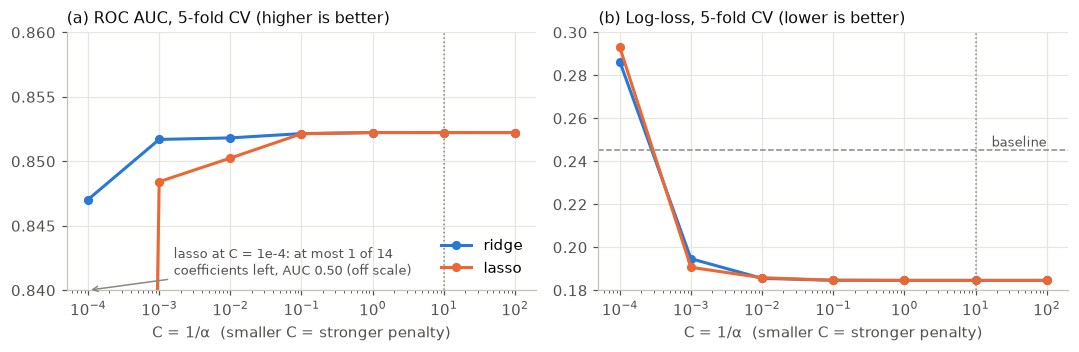

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
for pen, cor in [('ridge', AZUL), ('lasso', LARANJA)]:
    d = res_lr[res_lr.penalidade == pen].sort_values('C')
    axes[0].plot(d.C, d.auc, color=cor, marker='o', markersize=5, label=pen)
    axes[1].plot(d.C, d.log_loss, color=cor, marker='o', markersize=5, label=pen)
axes[0].set(title='(a) ROC AUC, 5-fold CV (higher is better)', xscale='log',
            xlabel='C = 1/α  (smaller C = stronger penalty)', ylim=(0.84, 0.86))
axes[1].set(title='(b) Log-loss, 5-fold CV (lower is better)', xscale='log',
            xlabel='C = 1/α  (smaller C = stronger penalty)', ylim=(0.18, 0.30))
base_ll = resultados_cv['Baseline (taxa base)']['log-loss (CV)']
axes[1].axhline(base_ll, color=CINZA, linestyle='--', linewidth=1)
axes[1].text(100, base_ll, 'baseline', color=TEXTO_2, va='bottom', ha='right', fontsize=8.5)
c_best = grade_lr.best_params_['modelo__C']
for ax in axes:
    ax.axvline(c_best, color=CINZA, linewidth=1, linestyle=':')
axes[0].legend(loc='lower right')
axes[0].annotate('lasso at C = 1e-4: at most 1 of 14\ncoefficients left, AUC 0.50 (off scale)', xy=(1e-4, 0.84), xytext=(1.6e-3, 0.8412),
                 fontsize=8.5, color=TEXTO_2, arrowprops=dict(arrowstyle='->', color=CINZA))
fig.tight_layout()
salvar(fig, 'fig_regularizacao')
plt.show()

**Leitura:**
- Com C ≥ 0,1 ridge e lasso empatam: AUC ≈ 0,852 e log-loss ≈ 0,185, e o C escolhido (10) é praticamente sem penalidade. Com 120 mil linhas e 14 colunas (n ≫ p), a variância dos coeficientes já é pequena e a penalidade quase não tem o que corrigir (Aula 11: ridge ajuda quando há poucas linhas, muitas colunas ou colunas quase colineares).
- Com penalidade muito forte (C = 10⁻⁴), o lasso corta quase tudo (no máximo 1 de 14 coeficientes sobra) e o modelo vira o baseline (AUC 0,5). O ridge encolhe sem zerar: o AUC (que só olha a ordem dos scores) continua em 0,847, mas o log-loss sobe para 0,286, **pior que o baseline** (0,245), porque as probabilidades ficam todas espremidas perto do mesmo valor.
- Isso mostra por que escolho C pelo log-loss e não pelo AUC: o AUC não vê que as probabilidades ficaram ruins.

In [11]:
avaliar_cv('LogReg com log (C escolhido)', grade_lr.best_estimator_)

AUC (CV)         0.8522
AUC desvio       0.0045
log-loss (CV)    0.1846
tempo (s)        4.0056
dtype: float64

### 4.3 Experimento: bins nas features contínuas

A EDA mostrou relações não lineares (o rotativo, por exemplo). Como o modelo é linear em β, posso dar a ele uma coluna 0/1 por faixa de valor (20 quantis), na linha da ideia de WOE/binning que comecei no `01_eda` para a idade. As contagens de atraso ficam em log: elas são ~85% zeros e os quantis colapsariam num bin só.

In [12]:
CONTINUAS = ['RevolvingUtilizationOfUnsecuredLines', 'age', 'DebtRatio',
             'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans']
CONTAGENS = [c for c in FEATURES_NUM if c not in CONTINUAS]

lr_bins = Pipeline([
    ('limpeza', FunctionTransformer(preparar_features)),
    ('imputacao', SimpleImputer(strategy='median').set_output(transform='pandas')),
    ('pre', ColumnTransformer([
        ('bins', KBinsDiscretizer(n_bins=20, encode='onehot', strategy='quantile',
                                  quantile_method='averaged_inverted_cdf'), CONTINUAS),
        ('cont', make_pipeline(FunctionTransformer(np.log1p), StandardScaler()), CONTAGENS),
        ('ind', 'passthrough', INDICADORES)])),
    ('modelo', LogisticRegression(max_iter=3000))])

with warnings.catch_warnings():
    warnings.simplefilter('ignore')  # avisos de bins repetidos em colunas com muitos empates
    display(avaliar_cv('LogReg com bins (experimento)', lr_bins, n_jobs=1))

AUC (CV)         0.8551
AUC desvio       0.0046
log-loss (CV)    0.1833
tempo (s)        2.0007
dtype: float64

Ganho de ~0,003 de AUC, dentro de um desvio padrão entre folds. Não compensa a perda de simplicidade (um coeficiente por faixa em vez de um por variável), então mantenho a regressão logística com log como modelo linear final. A diferença para a Random Forest (seção 5) não vem só de curvas em cada variável isolada; vem de **interações** entre variáveis, que a logística só captaria se eu criasse as colunas à mão (Aula 9, *logistic regression vs XGBoost*).

## 5. Random Forest

Modelo de comparação. Uma árvore faz perguntas sim/não sobre as colunas e captura não linearidades e interações automaticamente ("a renda só importa quando há atrasos"). Uma árvore sozinha tem variância alta; a floresta faz a média de muitas árvores treinadas em amostras bootstrap e com sorteio de colunas em cada divisão, o que reduz a variância (aula de 13/11).

O hiperparâmetro que mais importa aqui é `min_samples_leaf`: com folha de 1 amostra, cada árvore decora o treino. Uso 300 árvores e `max_features='sqrt'` (padrão), e escolho a folha pelo menor log-loss da validação cruzada.

In [13]:
grade_rf = GridSearchCV(
    pipeline_floresta(),
    {'modelo__min_samples_leaf': [1, 5, 20, 50, 100, 200]},
    cv=cv, scoring=METRICAS, refit='log_loss', return_train_score=True, n_jobs=1)
inicio = time.time()
grade_rf.fit(X_treino, y_treino)
print(f'{time.time() - inicio:.1f}s | melhor: {grade_rf.best_params_}')

res_rf = (pd.DataFrame(grade_rf.cv_results_)
          .assign(folha=lambda d: d.param_modelo__min_samples_leaf.astype(int),
                  auc_treino=lambda d: d.mean_train_auc, auc_validacao=lambda d: d.mean_test_auc,
                  auc_dp=lambda d: d.std_test_auc,
                  log_loss_treino=lambda d: -d.mean_train_log_loss,
                  log_loss_validacao=lambda d: -d.mean_test_log_loss)
          [['folha', 'auc_treino', 'auc_validacao', 'auc_dp', 'log_loss_treino', 'log_loss_validacao']])
res_rf.round(4)

132.1s | melhor: {'modelo__min_samples_leaf': 20}


,folha,auc_treino,auc_validacao,auc_dp,log_loss_treino,log_loss_validacao
0,1,1.0000,0.8431,0.0026,0.0419,0.2391
1,5,0.9755,0.8585,0.0028,0.1187,0.1806
2,20,0.9273,0.8633,0.0032,0.1540,0.1785
3,50,0.9001,0.8641,0.0030,0.1667,0.1787
4,100,0.8853,0.8636,0.0030,0.1729,0.1795
5,200,0.8746,0.8625,0.0030,0.1778,0.1812


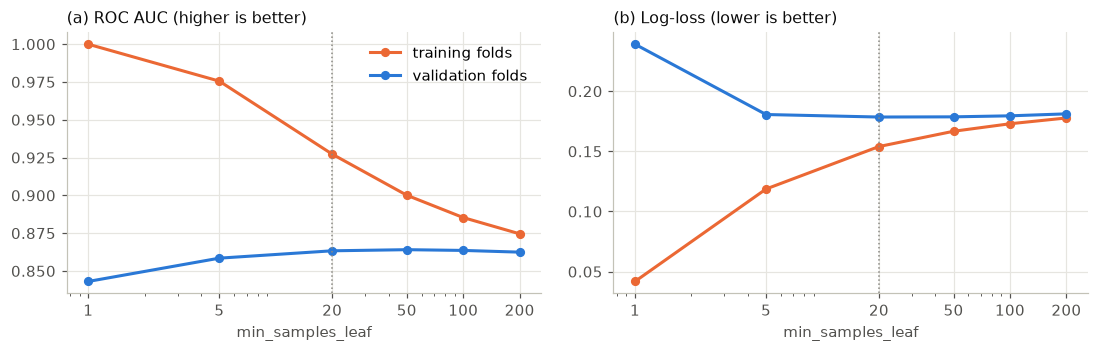

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
x = res_rf.folha
axes[0].plot(x, res_rf.auc_treino, color=LARANJA, marker='o', markersize=5, label='training folds')
axes[0].plot(x, res_rf.auc_validacao, color=AZUL, marker='o', markersize=5, label='validation folds')
axes[0].set(title='(a) ROC AUC (higher is better)', xscale='log', xlabel='min_samples_leaf')
axes[1].plot(x, res_rf.log_loss_treino, color=LARANJA, marker='o', markersize=5, label='training folds')
axes[1].plot(x, res_rf.log_loss_validacao, color=AZUL, marker='o', markersize=5, label='validation folds')
axes[1].set(title='(b) Log-loss (lower is better)', xscale='log', xlabel='min_samples_leaf')
folha_best = grade_rf.best_params_['modelo__min_samples_leaf']
for ax in axes:
    ax.axvline(folha_best, color=CINZA, linewidth=1, linestyle=':')
    ax.set_xticks(list(x)); ax.set_xticklabels([str(v) for v in x])
axes[0].legend(loc='upper right')
fig.tight_layout()
salvar(fig, 'fig_floresta')
plt.show()

**Leitura (viés-variância, Aula 6):** com folha de 1 amostra o AUC de treino é praticamente 1 e o de validação é o pior da grade, um caso clássico de overfitting. Aumentar a folha deixa cada árvore mais simples: o treino piora, a validação melhora até um ponto e depois volta a cair (underfitting).

In [15]:
avaliar_cv('Random Forest (folha escolhida)', grade_rf.best_estimator_, n_jobs=1)

AUC (CV)          0.8633
AUC desvio        0.0032
log-loss (CV)     0.1785
tempo (s)        17.1257
dtype: float64

In [16]:
tabela_cv = pd.DataFrame(resultados_cv).T
tabela_cv.round(4)

,AUC (CV),AUC desvio,log-loss (CV),tempo (s)
Baseline (taxa base),0.5000,0.0000,0.2454,2.1823
LogReg sem log,0.8507,0.0043,0.1878,0.8666
LogReg com log,0.8522,0.0045,0.1846,0.8197
LogReg com log (C escolhido),0.8522,0.0045,0.1846,4.0056
LogReg com bins (experimento),0.8551,0.0046,0.1833,2.0007
Random Forest (folha escolhida),0.8633,0.0032,0.1785,17.1257


## 6. Avaliação final no conjunto de teste

Agora, e só agora, abro o teste. Os dois modelos finais foram reajustados em todo o treino (`best_estimator_`) com os hiperparâmetros escolhidos na validação cruzada.

In [17]:
modelos_finais = {
    'Baseline': DummyClassifier(strategy='prior').fit(X_treino, y_treino),
    'Logistic regression': grade_lr.best_estimator_,
    'Random forest': grade_rf.best_estimator_,
}
proba_teste = {nome: m.predict_proba(X_teste)[:, 1] for nome, m in modelos_finais.items()}

tabela_teste = pd.DataFrame({
    nome: {'AUC (teste)': roc_auc_score(y_teste, p),
           'log-loss (teste)': log_loss(y_teste, p),
           'acurácia @0.5 (teste)': accuracy_score(y_teste, p >= 0.5)}
    for nome, p in proba_teste.items()}).T
tabela_teste.round(4)

,AUC (teste),log-loss (teste),acurácia @0.5 (teste)
Baseline,0.5000,0.2454,0.9332
Logistic regression,0.8584,0.1827,0.9366
Random forest,0.8663,0.1771,0.9368


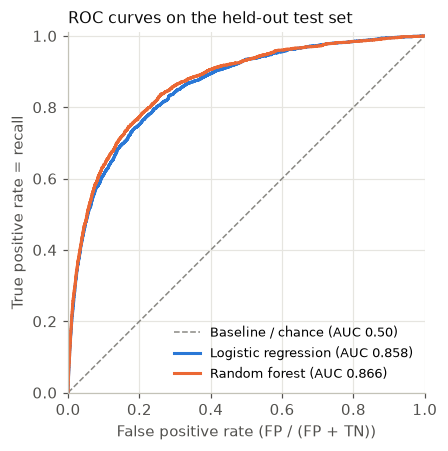

In [18]:
fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.plot([0, 1], [0, 1], color=CINZA, linestyle='--', linewidth=1, label='Baseline / chance (AUC 0.50)')
for nome, cor in [('Logistic regression', AZUL), ('Random forest', LARANJA)]:
    fpr, tpr, _ = roc_curve(y_teste, proba_teste[nome])
    ax.plot(fpr, tpr, color=cor, label=f'{nome} (AUC {roc_auc_score(y_teste, proba_teste[nome]):.3f})')
ax.set(title='ROC curves on the held-out test set', xlabel='False positive rate (FP / (FP + TN))',
       ylabel='True positive rate = recall', xlim=(0, 1), ylim=(0, 1.01))
ax.set_aspect('equal')
ax.legend(loc='lower right', fontsize=8.5)
fig.tight_layout()
salvar(fig, 'fig_roc')
plt.show()

## 7. Limiar de decisão

O modelo dá uma probabilidade; o limiar é uma decisão de negócio (Aula 9, *is 0.5 always the right threshold?*). Aqui o erro caro é emprestar para quem vai inadimplir (falso negativo). Com 0,5, quase ninguém é sinalizado e a maior parte dos inadimplentes passa.

Como o limiar também é um hiperparâmetro, ele é escolhido **na validação**, nunca no teste: uso as probabilidades *out-of-fold* do treino (`cross_val_predict`), em que cada cliente é pontuado por um modelo que não o viu. Critério ilustrativo: o maior limiar que ainda captura **pelo menos 70% dos inadimplentes** (recall ≥ 0,70).

In [19]:
proba_oof = {nome: cross_val_predict(modelos_finais[nome], X_treino, y_treino, cv=cv,
                                     method='predict_proba')[:, 1]
             for nome in ['Logistic regression', 'Random forest']}

def resumo_limiar(y_true, proba, t):
    pred = proba >= t
    return {'precisão': precision_score(y_true, pred, zero_division=0),
            'recall': recall_score(y_true, pred),
            '% sinalizados': pred.mean()}

linhas = []
for nome, p in proba_oof.items():
    for t in [0.5, 0.3, 0.2, 0.1, round(taxa_base, 3)]:
        linhas.append({'modelo': nome, 'limiar': t, **resumo_limiar(y_treino, p, t)})
pd.DataFrame(linhas).set_index(['modelo', 'limiar']).round(3)

precisão  recall  % sinalizados
modelo              limiar                                 
Logistic regression 0.500      0.581   0.190          0.022
                    0.300      0.498   0.319          0.043
                    0.200      0.425   0.430          0.068
                    0.100      0.281   0.620          0.148
                    0.067      0.207   0.747          0.241
Random forest       0.500      0.625   0.134          0.014
                    0.300      0.466   0.389          0.056
                    0.200      0.383   0.519          0.091
                    0.100      0.258   0.703          0.182
                    0.067      0.207   0.790          0.255

In [20]:
RECALL_ALVO = 0.70
limiares = {}
for nome, p in proba_oof.items():
    prec, rec, ts = precision_recall_curve(y_treino, p)
    limiares[nome] = ts[rec[:-1] >= RECALL_ALVO].max()

linhas = []
for nome, t in limiares.items():
    pred = proba_teste[nome] >= t
    tn, fp, fn, tp = confusion_matrix(y_teste, pred).ravel()
    linhas.append({'modelo': nome, 'limiar (escolhido na CV)': t, 'TP': tp, 'FN': fn, 'FP': fp, 'TN': tn,
                   **resumo_limiar(y_teste, proba_teste[nome], t)})
tabela_limiar = pd.DataFrame(linhas).set_index('modelo')
tabela_limiar.round(3)

,limiar (escolhido na CV),TP,FN,FP,TN,precisão,recall,% sinalizados
modelo,,,,,,,,
Logistic regression,0.079,1421,584,4590,23405,0.236,0.709,0.200
Random forest,0.101,1413,592,3949,24046,0.264,0.705,0.179


In [21]:
# Na linguagem de crédito: quantos o banco aprova e qual a inadimplência entre os aprovados
aprovados = tabela_limiar.TN + tabela_limiar.FN
credito = pd.DataFrame({
    'aprovados': aprovados,
    'taxa de aprovação': aprovados / len(y_teste),
    'inadimplência nos aprovados': tabela_limiar.FN / aprovados,
    'Gini (2·AUC − 1)': [2 * roc_auc_score(y_teste, proba_teste[n]) - 1 for n in tabela_limiar.index],
})
print(f'inadimplência da carteira de teste: {y_teste.mean():.2%}')
credito.round(4)

inadimplência da carteira de teste: 6.68%


,aprovados,taxa de aprovação,inadimplência nos aprovados,Gini (2·AUC − 1)
modelo,,,,
Logistic regression,23989,0.7996,0.0243,0.7169
Random forest,24638,0.8213,0.0240,0.7326


Com o limiar escolhido na validação, os dois modelos capturam cerca de 70% dos inadimplentes do teste, o que mostra que o limiar generalizou. O preço é a precisão: só uma fração dos clientes sinalizados de fato inadimpliria. Em uma aplicação real, o limiar sairia do custo de cada erro (perda média de um calote × lucro perdido de recusar um bom pagador), e não de um recall fixo.

## 8. Interpretação

**Regressão logística:** e^β é o odds ratio (Aula 9). Para as features numéricas (padronizadas), é o quanto as chances de inadimplência são multiplicadas quando a feature sobe 1 desvio padrão (na escala log, para as de cauda longa), mantendo as outras fixas. Para os indicadores 0/1, é o efeito de a flag estar ligada.

**Random Forest:** importância por redução média de impureza (Gini), somada nas divisões de todas as árvores. Ela não tem sinal (não diz se aumenta ou diminui o risco) e tende a favorecer features contínuas com muitos valores possíveis.

In [22]:
lr_final = grade_lr.best_estimator_
coefs = pd.Series(lr_final['modelo'].coef_[0], index=lr_final['pre'].get_feature_names_out())
odds = np.exp(coefs).rename('odds ratio')

rf_final = grade_rf.best_estimator_
importancias = pd.Series(rf_final['modelo'].feature_importances_,
                         index=rf_final['imputacao'].get_feature_names_out()).rename('importância')

interpretacao = pd.concat([coefs.rename('β'), odds, importancias], axis=1)
interpretacao.index = interpretacao.index.map(NOMES_CURTOS)
interpretacao.sort_values('importância', ascending=False).round(3)

,β,odds ratio,importância
Times 90+ days late,0.331,1.393,0.267
Revolving utilization,0.678,1.970,0.215
Times 60-89 days late,0.203,1.224,0.135
Times 30-59 days late,0.338,1.402,0.117
Debt ratio,-0.055,0.946,0.061
Age,-0.235,0.790,0.057
Monthly income,-0.051,0.950,0.051
Open credit lines,0.067,1.070,0.047
Real-estate loans,0.078,1.081,0.017
Flag: late codes 96/98,2.530,12.551,0.015


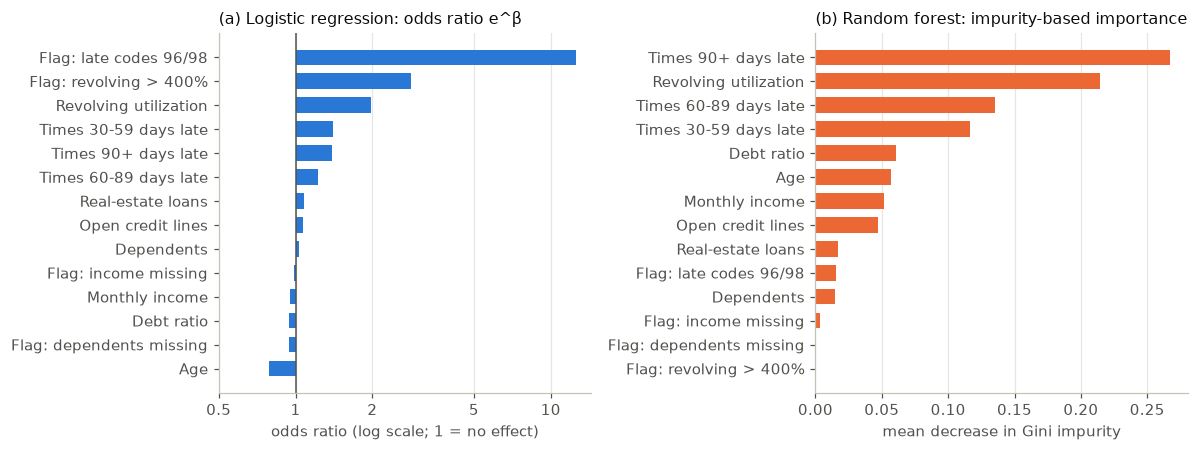

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

d = odds.rename(index=NOMES_CURTOS).sort_values()
axes[0].barh(d.index, d.values - 1, left=1, color=AZUL, height=0.65)
axes[0].axvline(1, color=TEXTO_2, linewidth=1)
axes[0].set_xscale('log')
axes[0].set_xticks([0.5, 1, 2, 5, 10]); axes[0].set_xticklabels(['0.5', '1', '2', '5', '10'])
axes[0].minorticks_off()
axes[0].set(title='(a) Logistic regression: odds ratio e^β', xlabel='odds ratio (log scale; 1 = no effect)')
axes[0].grid(axis='y', visible=False)

d = importancias.rename(index=NOMES_CURTOS).sort_values()
axes[1].barh(d.index, d.values, color=LARANJA, height=0.65)
axes[1].set(title='(b) Random forest: impurity-based importance', xlabel='mean decrease in Gini impurity')
axes[1].grid(axis='y', visible=False)

fig.tight_layout()
salvar(fig, 'fig_interpretacao')
plt.show()

## 9. Submissão Kaggle (opcional)

Reajusto a Random Forest escolhida com todos os 150 mil clientes rotulados e gero as probabilidades para o `cs-test.csv`. Para submeter: `kaggle competitions submit -c GiveMeSomeCredit -f submissions/submission_rf.csv -m "RF"`.

In [24]:
teste_kaggle = carregar_teste_kaggle()
rf_completo = clone(grade_rf.best_estimator_).fit(X, y)
submissao = pd.DataFrame({'Id': teste_kaggle.index,
                          'Probability': rf_completo.predict_proba(teste_kaggle.drop(columns=TARGET_NAME))[:, 1]})
SUB_DIR = RAIZ / 'submissions'
SUB_DIR.mkdir(exist_ok=True)
submissao.to_csv(SUB_DIR / 'submission_rf.csv', index=False)
submissao.describe().round(4)

,Id,Probability
count,101503.0000,101503.0000
mean,50752.0000,0.0670
std,29301.5365,0.1097
min,1.0000,0.0006
25%,25376.5000,0.0092
50%,50752.0000,0.0229
75%,76127.5000,0.0687
max,101503.0000,0.8193


## 10. Conclusões

| Modelo | AUC (CV) | AUC (teste) | log-loss (teste) |
|---|---|---|---|
| Baseline (taxa base) | 0,500 | 0,500 | 0,245 |
| Regressão logística (log, ridge, C = 10) | 0,852 | 0,858 | 0,183 |
| Random Forest (300 árvores, folha ≥ 20) | 0,863 | 0,866 | 0,177 |

- **A pergunta tem resposta útil:** os dois modelos ordenam bem os clientes (AUC 0,86–0,87 no teste, contra 0,5 do baseline), e os números do teste batem com os da validação cruzada, sinal de que não houve leakage nem escolha otimista.
- **A Random Forest ganha, mas por pouco:** +0,008 de AUC. A regressão logística entrega quase o mesmo poder de ordenação com um coeficiente explicável por variável.
- **O que pesa no risco:** atrasos anteriores (as três contagens), uso do rotativo e, no sentido contrário, a idade. Os indicadores criados na EDA importam: a flag dos códigos 96/98 multiplica as chances de inadimplência por ~12,6 na logística.
- **O que não ajudou:** regularização (n ≫ p), bins nas contínuas (+0,003) e a soma ponderada dos atrasos (combinação linear de colunas existentes). O log nas features assimétricas ajudou pouco (+0,0015).
- **Acurácia engana:** com limiar 0,5 os modelos acertam 93,7%, contra 93,3% do "todo mundo paga". Com o limiar escolhido na validação (recall ≥ 70%), sinalizam ~18–20% dos clientes e capturam ~70% dos inadimplentes do teste, com precisão de 24–26%.

**Próximos passos:** gradient boosting (o "XGBoost" da Aula 9); limiar a partir do custo real de cada erro; checar a calibração das probabilidades; investigar as 609 linhas duplicadas; discutir se a idade deve entrar num modelo de crédito (Aula 9, *when a model learns a prejudice*).

## 11. Figuras para os slides

Os mesmos gráficos das seções anteriores, redesenhados para a apresentação com o tema padrão do seaborn (fundo cinza com grade branca, paleta `deep`), em letras grandes o bastante para projetar. Cada figura é salva com o tamanho exato do espaço que ocupa no slide (100 px por polegada). Nas figuras com os dois modelos, a regressão logística é sempre azul e a floresta, laranja. Os arquivos vão para `docs/apresentacao/deck/assets/`.

In [25]:
import seaborn as sns

SLIDE_DIR = RAIZ / 'docs' / 'apresentacao' / 'deck' / 'assets'
SLIDE_DIR.mkdir(parents=True, exist_ok=True)
AZUL, LARANJA = sns.color_palette('deep')[:2]
CINZA, TEXTO = '0.45', '0.2'
TEMA_SLIDE = {
    **sns.axes_style('darkgrid'),
    **sns.plotting_context('notebook', font_scale=1.5),
    'axes.prop_cycle': plt.cycler(color=sns.color_palette('deep')),
    'figure.facecolor': 'white', 'savefig.facecolor': 'white',
    'savefig.dpi': 200, 'savefig.bbox': 'standard',
}

def figura_slide(largura_px, altura_px, **kw):
    return plt.subplots(figsize=(largura_px / 100, altura_px / 100), layout='constrained', **kw)

def salvar_slide(fig, nome):
    fig.savefig(SLIDE_DIR / f'{nome}.png')
    plt.close(fig)
    print('salvo:', nome)

In [26]:
# EDA (seção 1): taxa de inadimplência por atrasos, rotativo, idade e flags
with plt.rc_context(TEMA_SLIDE):
    fig, axes = figura_slide(1664, 400, ncols=4, sharey=True)
    atraso = eda['NumberOfTime30-59DaysPastDueNotWorse'].clip(upper=5)
    t = eda.groupby(atraso)['alvo'].mean()
    axes[0].bar(['0', '1', '2', '3', '4', '5+'], t.values, color=AZUL, width=0.7)
    axes[0].set(title='(a) 30–59 days late', xlabel='times')
    decil = pd.qcut(eda['RevolvingUtilizationOfUnsecuredLines'], 10, labels=False) + 1
    t = eda.groupby(decil)['alvo'].mean()
    axes[1].plot(t.index, t.values, color=AZUL, marker='o')
    axes[1].set(title='(b) Revolving use', xlabel='decile', xticks=[1, 4, 7, 10], xlim=(0.3, 10.7))
    faixa = pd.cut(eda['age'], [20, 30, 40, 50, 60, 70, 110], right=False)
    t = eda.groupby(faixa, observed=True)['alvo'].mean()
    axes[2].plot(range(len(t)), t.values, color=AZUL, marker='o')
    axes[2].set(title='(c) Age', xlabel='age band', xticks=range(len(t)),
                xticklabels=['20s', '30s', '40s', '50s', '60s', '70+'], xlim=(-0.7, 5.7))
    axes[3].bar(['Has\nincome', 'No\nincome', 'Codes\n96/98'], taxas, color=AZUL, width=0.6)
    axes[3].set(title='(d) Flags')
    for ax in axes:
        ax.axhline(taxa_base, color=CINZA, linestyle='--', linewidth=1.5)
        ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
        ax.grid(axis='x', visible=False)
    axes[0].set_ylabel('default rate')
    axes[1].text(0.8, taxa_base + 0.015, f'all clients {taxa_base:.1%}', color=TEXTO)
    salvar_slide(fig, 'slide_eda')

salvo: slide_eda


In [27]:
# Regressão logística (seção 4.2): ridge x lasso ao longo de C
with plt.rc_context(TEMA_SLIDE):
    fig, axes = figura_slide(1664, 440, ncols=2)
    for pen, cor in [('ridge', AZUL), ('lasso', LARANJA)]:
        d = res_lr[res_lr.penalidade == pen].sort_values('C')
        axes[0].plot(d.C, d.auc, color=cor, marker='o', label=pen)
        axes[1].plot(d.C, d.log_loss, color=cor, marker='o', label=pen)
    axes[0].set(title='(a) AUC, 5-fold CV (higher is better)', xscale='log',
                xlabel='C = 1/α (left: stronger penalty)', ylim=(0.84, 0.86))
    axes[1].set(title='(b) Log-loss, 5-fold CV (lower is better)', xscale='log',
                xlabel='C = 1/α (left: stronger penalty)', ylim=(0.18, 0.30))
    axes[1].axhline(base_ll, color=CINZA, linestyle='--', linewidth=1.5)
    axes[1].text(100, base_ll + 0.004, 'constant baseline', color=TEXTO, ha='right')
    for ax in axes:
        ax.axvline(c_best, color=CINZA, linewidth=1.5, linestyle=':')
    axes[0].text(c_best * 0.8, 0.8415, f'chosen\nC = {c_best:g}', color=TEXTO, ha='right')
    axes[0].annotate('lasso at C = 1e-4:\nAUC 0.50', xy=(1e-4, 0.84), xytext=(1.8e-3, 0.8418),
                     color=TEXTO, arrowprops=dict(arrowstyle='->', color=CINZA))
    axes[1].legend(loc='upper right')
    salvar_slide(fig, 'slide_regularizacao')

salvo: slide_regularizacao


In [28]:
# Random Forest (seção 5): treino x validação ao longo do tamanho da folha
with plt.rc_context(TEMA_SLIDE):
    fig, axes = figura_slide(1664, 440, ncols=2)
    x = res_rf.folha
    for ax, col, titulo in [(axes[0], 'auc', '(a) AUC (higher is better)'),
                            (axes[1], 'log_loss', '(b) Log-loss (lower is better)')]:
        ax.plot(x, res_rf[f'{col}_treino'], color=AZUL, linestyle='--', marker='o', label='training folds')
        ax.plot(x, res_rf[f'{col}_validacao'], color=LARANJA, marker='o', label='validation folds')
        ax.axvline(folha_best, color=CINZA, linewidth=1.5, linestyle=':')
        ax.set(title=titulo, xscale='log', xlabel='min_samples_leaf (left: deeper trees)')
        ax.set_xticks(list(x)); ax.set_xticklabels([str(v) for v in x]); ax.minorticks_off()
    axes[0].legend(loc='upper right')
    salvar_slide(fig, 'slide_floresta')

salvo: slide_floresta


In [29]:
# Curvas ROC no teste (seção 6)
with plt.rc_context(TEMA_SLIDE):
    fig, ax = figura_slide(600, 600)
    ax.plot([0, 1], [0, 1], color=CINZA, linestyle='--', linewidth=1.5, label='Coin flip (0.500)')
    for nome, cor in [('Logistic regression', AZUL), ('Random forest', LARANJA)]:
        fpr, tpr, _ = roc_curve(y_teste, proba_teste[nome])
        ax.plot(fpr, tpr, color=cor, label=f'{nome} ({roc_auc_score(y_teste, proba_teste[nome]):.3f})')
    ax.set(xlabel='False-alarm rate', ylabel='Defaulters caught (recall)', xlim=(0, 1), ylim=(0, 1.01))
    ax.legend(loc='lower right', title='Test AUC', title_fontsize=18, alignment='left')
    salvar_slide(fig, 'slide_roc')

salvo: slide_roc


In [30]:
# Interpretação (seção 8): odds ratios da logística e importâncias da floresta
with plt.rc_context(TEMA_SLIDE):
    fig, axes = figura_slide(1664, 560, ncols=2)
    d = odds.rename(index=NOMES_CURTOS).sort_values()
    axes[0].barh(d.index, d.values - 1, left=1, color=AZUL, height=0.65)
    axes[0].axvline(1, color=CINZA, linewidth=1.5)
    axes[0].set_xscale('log'); axes[0].minorticks_off()
    axes[0].set_xticks([0.5, 1, 2, 5, 10]); axes[0].set_xticklabels(['0.5', '1', '2', '5', '10'])
    axes[0].set(title='(a) Logistic regression: odds ratio e^β', xlabel='odds ratio (1 = no effect)')
    d = importancias.rename(index=NOMES_CURTOS).sort_values()
    axes[1].barh(d.index, d.values, color=LARANJA, height=0.65)
    axes[1].set(title='(b) Random forest: importance', xlabel='mean decrease in Gini impurity')
    for ax in axes:
        ax.grid(axis='y', visible=False)
    salvar_slide(fig, 'slide_interpretacao')

salvo: slide_interpretacao
